# Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá

**Bộ dữ liệu:** AirPassengers (144 quan sát hàng tháng từ 1949 đến 1960)  
**Dữ liệu:** `data/raw/AirPassengers.csv` trong repository. Notebook tự chia Train (80%) và Test (20%) theo đúng thứ tự thời gian nếu chưa có dữ liệu đã chia sẵn trong `data/processed/`.  
**Thư viện:** `statsmodels`, `matplotlib`, `numpy`, `pandas`

> GitHub hiển thị các kết quả đã lưu trong notebook nhưng không chạy code. Để chạy lại, mở notebook bằng Google Colab/Jupyter và chọn **Run all**.

## Mục tiêu
1. Đọc dữ liệu chuỗi thời gian và chia train/test không xáo trộn.
2. Thiết lập, so sánh ARIMA(1,1,1) và ARIMA(2,1,1).
3. Chẩn đoán phần dư, dự báo và đánh giá bằng MAE, RMSE, MAPE, R².


---
## 0. Cấu hình môi trường & Import thư viện

In [1]:
import os
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

# Tìm thư mục gốc của repository, dù chạy từ Jupyter, Colab hay thư mục notebooks.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / 'data' / 'raw' / 'AirPassengers.csv').exists()), None)

# Trên Google Colab, clone repository nếu chưa có trong thư mục hiện tại.
if PROJECT_ROOT is None and 'google.colab' in sys.modules:
    import subprocess
    repo_dir = Path('/content/Lab_TimeSeries')
    if not (repo_dir / 'data' / 'raw' / 'AirPassengers.csv').exists():
        subprocess.run(['git', 'clone', 'https://github.com/OrangkillEmily/Lab_TimeSeries.git', str(repo_dir)], check=True)
    PROJECT_ROOT = repo_dir

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/AirPassengers.csv. Hãy chạy notebook trong thư mục repository "
        "Lab_TimeSeries hoặc mở bằng Google Colab từ GitHub."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.lab02_utils.modeling import fit_arima, fit_sarima, calculate_metrics

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    pass

print('Đã nạp thư viện và xác định được thư mục dự án.')


Đã nạp thư viện và xác định được thư mục dự án.


---
## 1. Đọc dữ liệu Train và Test từ `data/processed/`

> **Lưu ý kiến trúc:** Dữ liệu chuỗi thời gian đã được thực hiện tiền xử lý và chia tập **Train (80%) / Test (20%)** tại **Bài 1 (EDA)** mà không bị xáo trộn (`shuffle=False`), sau đó lưu vào thư mục `data/processed/`.  
> Ở Bài 5, ta nạp trực tiếp 2 tệp dữ liệu này để đảm bảo tính nhất quán và nguyên tắc chống rò rỉ thông tin (Data Leakage).

In [2]:
# Ưu tiên dùng tập train/test đã chia sẵn; nếu repository chưa có, chia từ AirPassengers.csv.
DATA_DIR_LAB02 = PROJECT_ROOT / 'data' / 'processed' / 'lab02'
DATA_DIR_DEFAULT = PROJECT_ROOT / 'data' / 'processed'
train_path = next((p for p in [
    DATA_DIR_LAB02 / 'train_data.csv',
    DATA_DIR_DEFAULT / 'train_data.csv'
] if p.exists()), None)
test_path = next((p for p in [
    DATA_DIR_LAB02 / 'test_data.csv',
    DATA_DIR_DEFAULT / 'test_data.csv'
] if p.exists()), None)

if train_path is not None and test_path is not None:
    print(f'Đang đọc tập Train từ: {train_path}')
    print(f'Đang đọc tập Test từ : {test_path}')
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
else:
    raw_path = PROJECT_ROOT / 'data' / 'raw' / 'AirPassengers.csv'
    print('Chưa có train/test trong data/processed; chia theo thời gian từ data/raw/AirPassengers.csv.')
    raw_df = pd.read_csv(raw_path)
    raw_df['Month'] = pd.to_datetime(raw_df['Month'])
    split_at = int(len(raw_df) * 0.8)
    train_df = raw_df.iloc[:split_at].copy()
    test_df = raw_df.iloc[split_at:].copy()

train_df['Month'] = pd.to_datetime(train_df['Month'])
test_df['Month'] = pd.to_datetime(test_df['Month'])
train = train_df.set_index('Month')['Passengers'].astype(float)
test = test_df.set_index('Month')['Passengers'].astype(float)

train.index = pd.DatetimeIndex(train.index).to_period('M').to_timestamp()
test.index = pd.DatetimeIndex(test.index).to_period('M').to_timestamp()

print(f'\nKích thước Train: {len(train)} quan sát ({train.index[0]:%Y-%m} → {train.index[-1]:%Y-%m})')
print(f'Kích thước Test : {len(test)} quan sát ({test.index[0]:%Y-%m} → {test.index[-1]:%Y-%m})')


Chưa có train/test trong data/processed; chia theo thời gian từ data/raw/AirPassengers.csv.

Kích thước Train: 115 quan sát (1949-01 → 1958-07)
Kích thước Test : 29 quan sát (1958-08 → 1960-12)


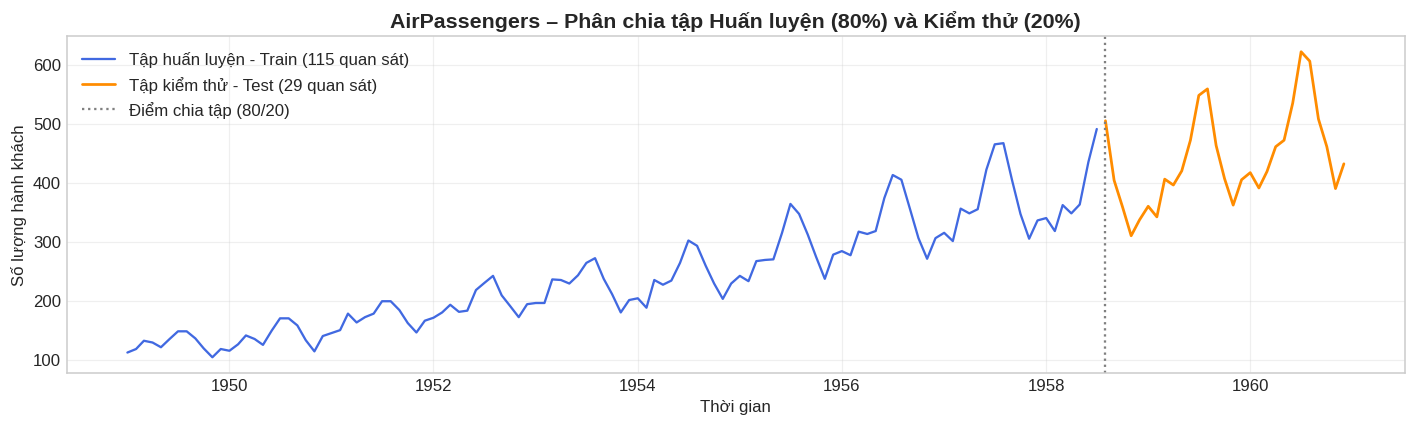

In [3]:
# Trực quan hóa tập dữ liệu Train (80%) và Test (20%)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train.index, train.values, color='royalblue', linewidth=1.5, label=f'Tập huấn luyện - Train ({len(train)} quan sát)')
ax.plot(test.index, test.values, color='darkorange', linewidth=1.8, label=f'Tập kiểm thử - Test ({len(test)} quan sát)')
ax.axvline(test.index[0], color='gray', linestyle=':', linewidth=1.5, label='Điểm chia tập (80/20)')
ax.set_title('AirPassengers – Phân chia tập Huấn luyện (80%) và Kiểm thử (20%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Thời gian')
ax.set_ylabel('Số lượng hành khách')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 2. Đề xuất mô hình ARIMA dựa trên ACF và PACF

### Nhận xét từ phân tích tại Bài 4 (trên chuỗi đã sai phân bậc 1):

| Đồ thị tương quan | Đặc điểm quan sát | Ý nghĩa / Gợi ý tham số |
|:---|:---|:---|
| **PACF** (Tự tương quan riêng) | Cắt cụt rõ rệt sau độ trễ 1 (lag 2 rơi vào trong dải tin cậy) | Gợi ý bậc tự hồi quy **$p = 1$** (hoặc thử nghiệm $p = 2$) |
| **ACF** (Tự tương quan) | Cắt cụt sau lag 1 hoặc giảm dần có chu kỳ | Gợi ý bậc trung bình động **$q = 1$** |
| **Sai phân** | Kiểm định ADF ở Bài 3 đã đạt chuẩn dừng với $d=1$ | Bậc sai phân **$d = 1$** |

**Đề xuất 2 mô hình thực nghiệm:**
1. **ARIMA(1,1,1):** Mô hình tinh gọn ($p=1, d=1, q=1$) bám sát điểm cắt cụt của PACF và ACF.
2. **ARIMA(2,1,1):** Mở rộng bậc AR lên $p=2$ để đối chiếu độ phức tạp và khả năng giảm sai số.

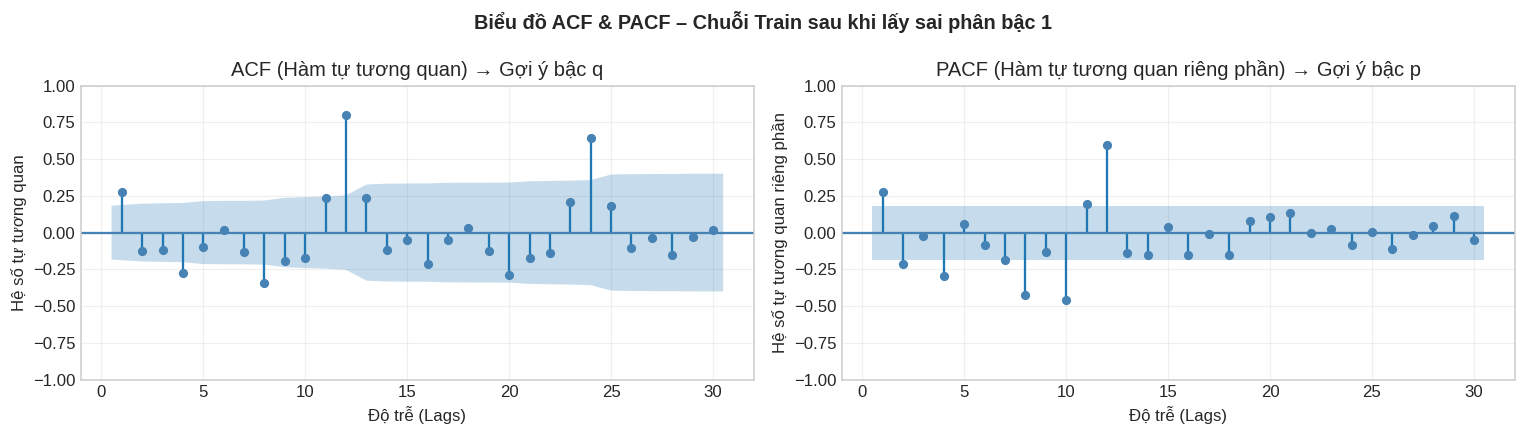

In [4]:
# Vẽ lại ACF và PACF trên chuỗi Train sau sai phân bậc 1 (d=1)
train_diff1 = train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Biểu đồ ACF & PACF – Chuỗi Train sau khi lấy sai phân bậc 1', fontsize=13, fontweight='bold')

plot_acf(train_diff1, lags=30, ax=axes[0], color='steelblue', zero=False)
axes[0].set_title('ACF (Hàm tự tương quan) → Gợi ý bậc q')
axes[0].set_xlabel('Độ trễ (Lags)')
axes[0].set_ylabel('Hệ số tự tương quan')
axes[0].grid(True, alpha=0.3)

plot_pacf(train_diff1, lags=30, ax=axes[1], method='ywm', color='steelblue', zero=False)
axes[1].set_title('PACF (Hàm tự tương quan riêng phần) → Gợi ý bậc p')
axes[1].set_xlabel('Độ trễ (Lags)')
axes[1].set_ylabel('Hệ số tự tương quan riêng phần')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Huấn luyện mô hình ARIMA – Ghi lại AIC và BIC

In [5]:
# Huấn luyện mô hình 1: ARIMA(1,1,1)
result_111 = fit_arima(train, order=(1, 1, 1))

In [6]:
# Huấn luyện mô hình 2: ARIMA(2,1,1)
result_211 = fit_arima(train, order=(2, 1, 1))

In [7]:
# Bảng so sánh chỉ số thông tin AIC và BIC
aic_bic_df = pd.DataFrame({
    'ARIMA(1,1,1)': {'AIC': result_111.aic, 'BIC': result_111.bic},
    'ARIMA(2,1,1)': {'AIC': result_211.aic, 'BIC': result_211.bic},
}).T.round(4)

print(' BẢNG SO SÁNH CHỈ SỐ THÔNG TIN AIC VÀ BIC:')
print(aic_bic_df.to_string())

best_aic = aic_bic_df['AIC'].idxmin()
best_bic = aic_bic_df['BIC'].idxmin()
print(f'\n Mô hình có AIC thấp nhất (tối ưu hơn): {best_aic} ({aic_bic_df.loc[best_aic, "AIC"]})')
print(f' Mô hình có BIC thấp nhất (tối ưu hơn): {best_bic} ({aic_bic_df.loc[best_bic, "BIC"]})')

 BẢNG SO SÁNH CHỈ SỐ THÔNG TIN AIC VÀ BIC:
                    AIC        BIC
ARIMA(1,1,1)  1058.2456  1066.4542
ARIMA(2,1,1)  1058.6476  1069.5924

 Mô hình có AIC thấp nhất (tối ưu hơn): ARIMA(1,1,1) (1058.2456)
 Mô hình có BIC thấp nhất (tối ưu hơn): ARIMA(1,1,1) (1066.4542)


### Ý nghĩa của AIC và BIC:
- **AIC (Akaike Information Criterion):** Đánh giá chất lượng khớp của mô hình và phạt độ phức tạp theo số lượng tham số. **Giá trị AIC càng nhỏ thì mô hình càng tốt.**
- **BIC (Bayesian Information Criterion):** Tương tự AIC nhưng mức độ phạt tham số nặng hơn, ưu tiên mô hình tinh giản nhằm ngăn chặn overfitting. **Giá trị BIC càng nhỏ càng tốt.**

---
## 4. Chẩn đoán phần dư (Residual Diagnostics)

> **Yêu cầu đối với phần dư chuẩn (Nhiễu trắng - White Noise):**
> - Giá trị trung bình của phần dư xấp xỉ 0 (Mean ≈ 0).
> - Không còn sự tự tương quan: Hệ số ACF của phần dư nằm trọn vẹn trong khoảng tin cậy 95% (±1.96/√n).
> - Kiểm định thống kê Ljung-Box có giá trị $p\text{-value} > 0.05$ (chưa đủ cơ sở bác bỏ H0: phần dư không tự tương quan).

In [8]:
def plot_residuals(result, model_name):
    """Vẽ đồ thị chẩn đoán phần dư: Phần dư theo thời gian + ACF của phần dư."""
    residuals = result.resid

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'Chẩn đoán phần dư (Residual Diagnostics) – {model_name}', fontsize=13, fontweight='bold')

    # Panel 1: Phần dư theo thời gian
    axes[0].plot(residuals, color='steelblue', linewidth=0.9, label='Phần dư (Residuals)')
    axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2, label='Đường trung bình = 0')
    axes[0].set_title('Phần dư theo thời gian')
    axes[0].set_xlabel('Thời gian')
    axes[0].set_ylabel('Giá trị phần dư')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Panel 2: ACF của Phần dư
    plot_acf(residuals.dropna(), lags=30, ax=axes[1], color='steelblue', zero=False)
    axes[1].set_title('Hàm tự tương quan (ACF) của phần dư')
    axes[1].set_xlabel('Độ trễ (Lags)')
    axes[1].set_ylabel('Hệ số tự tương quan')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Thống kê phần dư
    mean_res = residuals.mean()
    print(f' Phần dư – Mean: {mean_res:.6f}  ({"≈ 0 (Đạt tiêu chuẩn White Noise )" if abs(mean_res) < 1 else "Khác 0"})')
    print(f' Phần dư – Std : {residuals.std():.4f}')

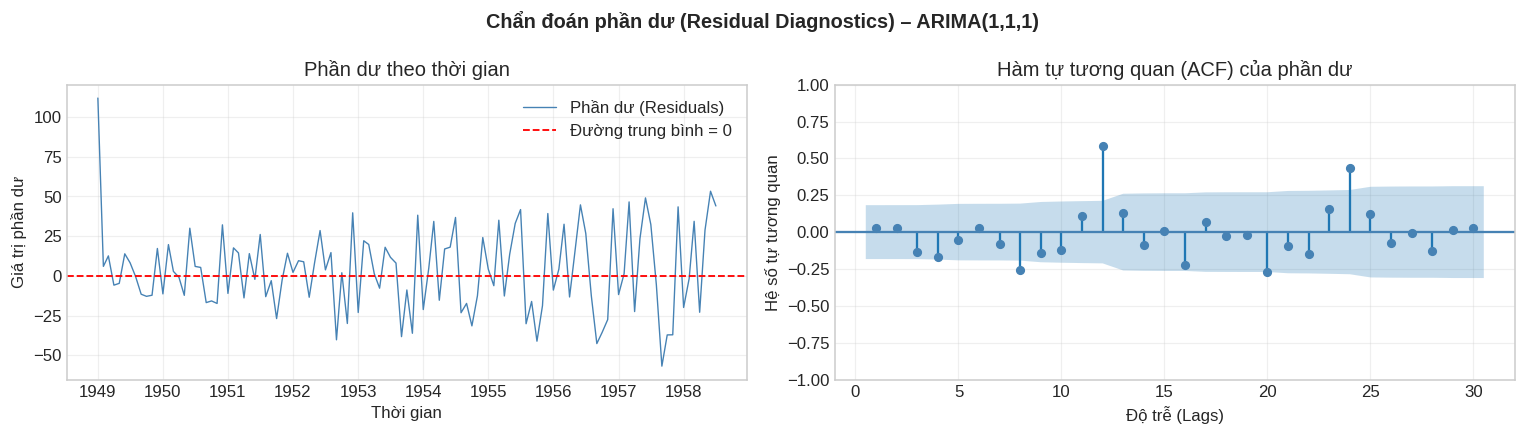

 Phần dư – Mean: 3.638595  (Khác 0)
 Phần dư – Std : 26.2720


In [9]:
# Chẩn đoán phần dư mô hình ARIMA(1,1,1)
plot_residuals(result_111, 'ARIMA(1,1,1)')

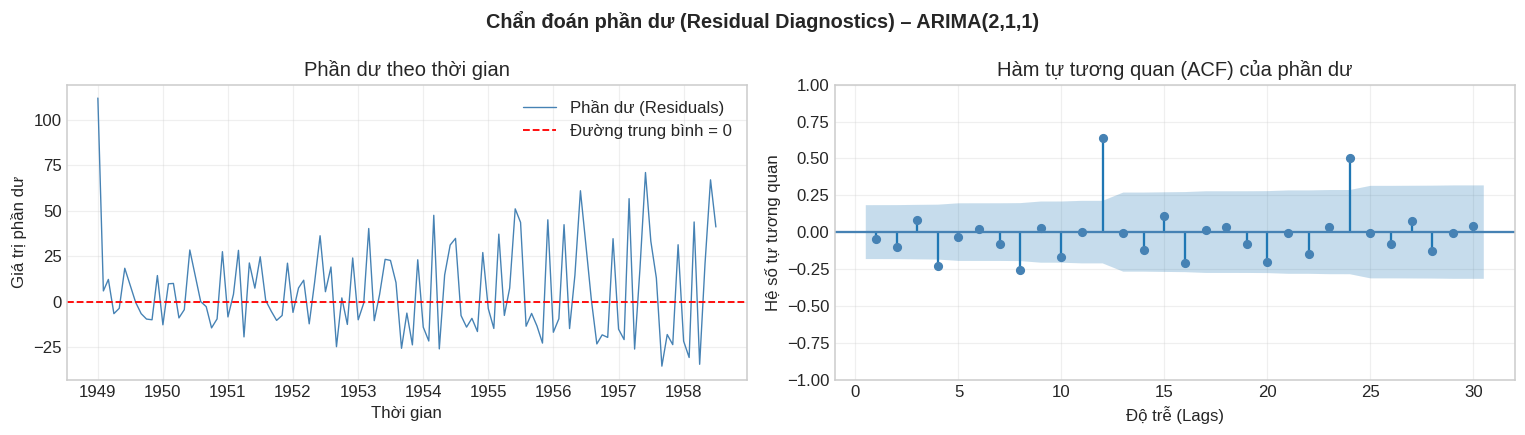

 Phần dư – Mean: 6.493943  (Khác 0)
 Phần dư – Std : 25.5652


In [10]:
# Chẩn đoán phần dư mô hình ARIMA(2,1,1)
plot_residuals(result_211, 'ARIMA(2,1,1)')

In [11]:
# Kiểm định định lượng Ljung-Box cho phần dư (H0: Phần dư không có tự tương quan)
print(' KIỂM ĐỊNH LJUNG-BOX (H0: Phần dư độc lập, không tự tương quan):')
print('-' * 70)
for name, res in [('ARIMA(1,1,1)', result_111), ('ARIMA(2,1,1)', result_211)]:
    lb = acorr_ljungbox(res.resid.dropna(), lags=[1, 10, 20], return_df=True)
    p1 = lb['lb_pvalue'].iloc[0]
    p10 = lb['lb_pvalue'].iloc[1]
    p20 = lb['lb_pvalue'].iloc[2]
    print(f'\n  Mô hình {name}:')
    print(f'    Độ trễ Lag=1 : p-value = {p1:.4f}  ({"Đạt White Noise  (p > 0.05)" if p1 > 0.05 else "Có tự tương quan"})')
    print(f'    Độ trễ Lag=10: p-value = {p10:.4f}  ({"Đạt White Noise  (p > 0.05)" if p10 > 0.05 else "Có tự tương quan"})')
    print(f'    Độ trễ Lag=20: p-value = {p20:.4f}  ({"Đạt White Noise  (p > 0.05)" if p20 > 0.05 else "Có tự tương quan"})')

 KIỂM ĐỊNH LJUNG-BOX (H0: Phần dư độc lập, không tự tương quan):
----------------------------------------------------------------------

  Mô hình ARIMA(1,1,1):
    Độ trễ Lag=1 : p-value = 0.7553  (Đạt White Noise  (p > 0.05))
    Độ trễ Lag=10: p-value = 0.0291  (Có tự tương quan)
    Độ trễ Lag=20: p-value = 0.0000  (Có tự tương quan)

  Mô hình ARIMA(2,1,1):
    Độ trễ Lag=1 : p-value = 0.6224  (Đạt White Noise  (p > 0.05))
    Độ trễ Lag=10: p-value = 0.0175  (Có tự tương quan)
    Độ trễ Lag=20: p-value = 0.0000  (Có tự tương quan)


### Nhận xét chẩn đoán phần dư:
- **Tính trung bình:** Cần xem giá trị trung bình phần dư cùng đồ thị phần dư để đánh giá sai lệch hệ thống.
- **Kiểm định tự tương quan:** Với ARIMA(1,1,1), Ljung–Box tại lag 1 có p-value khoảng 0.7553 (> 0.05), nhưng tại lag 10 và 20 p-value lần lượt khoảng 0.0291 và nhỏ hơn 0.05. Vì vậy, chưa thể kết luận phần dư là nhiễu trắng ở các độ trễ lớn hơn.
- **Đặc tính mùa vụ:** Chuỗi `AirPassengers` có tính mùa vụ mạnh (chu kỳ 12 tháng). ARIMA phi mùa vụ chưa mô hình hóa đầy đủ thành phần này; có thể tiếp tục xem xét SARIMA ở Bài 6.


---
## 5. Dự báo (Forecasting) trên tập Test

In [12]:
def forecast_and_plot(result, train, test, model_name):
    """Dự báo trên tập test và vẽ biểu đồ Train / Test / Forecast."""
    forecast_obj = result.get_forecast(steps=len(test))
    fc_mean = forecast_obj.predicted_mean
    conf_int = forecast_obj.conf_int()
    fc_mean.index = test.index
    conf_int.index = test.index

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(train.index, train.values, color='royalblue',
            linewidth=1.5, label='Tập huấn luyện - Train (Thực tế)')
    ax.plot(test.index, test.values, color='darkorange',
            linewidth=2, label='Tập kiểm thử - Test (Thực tế)', marker='o', markersize=4)
    ax.plot(fc_mean.index, fc_mean.values, color='crimson',
            linewidth=2, linestyle='--', label=f'Dự báo (Forecast) – {model_name}',
            marker='x', markersize=5)
    ax.fill_between(conf_int.index,
                    conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                    color='crimson', alpha=0.12, label='Khoảng tin cậy 95% (95% CI)')
    ax.set_title(f'Dự báo chuỗi thời gian trên tập Test – {model_name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Thời gian')
    ax.set_ylabel('Số lượng hành khách')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return fc_mean

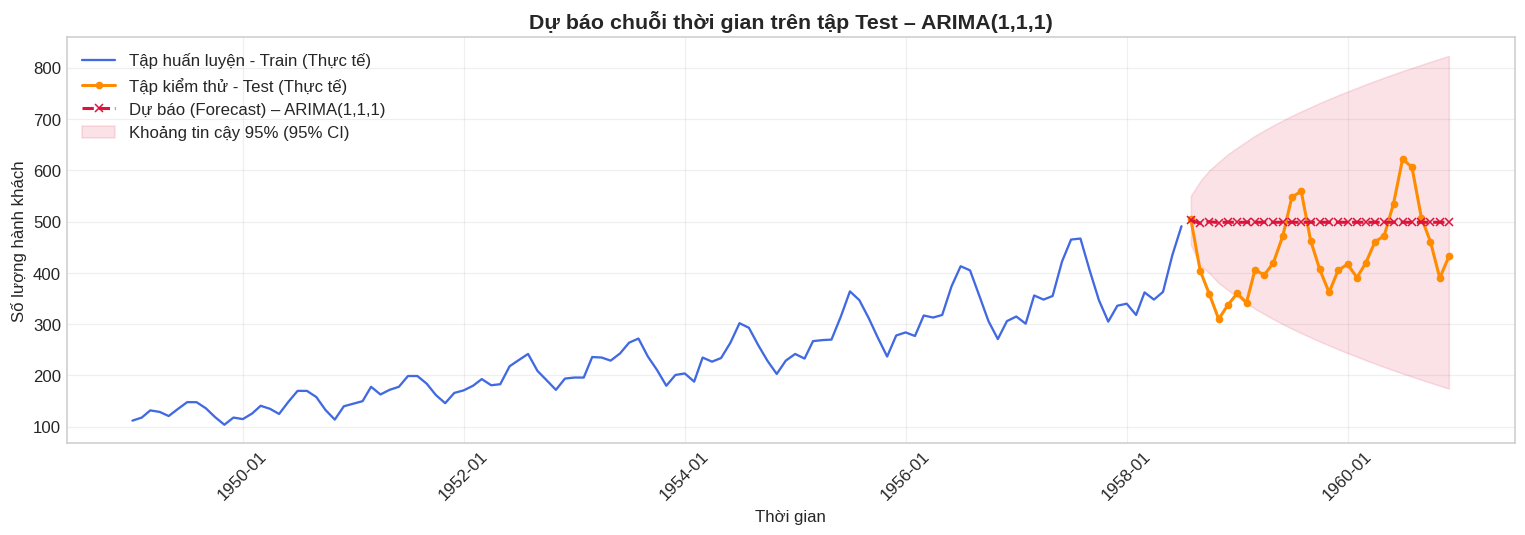

In [13]:
# Dự báo tập Test với mô hình ARIMA(1,1,1)
forecast_111 = forecast_and_plot(result_111, train, test, 'ARIMA(1,1,1)')

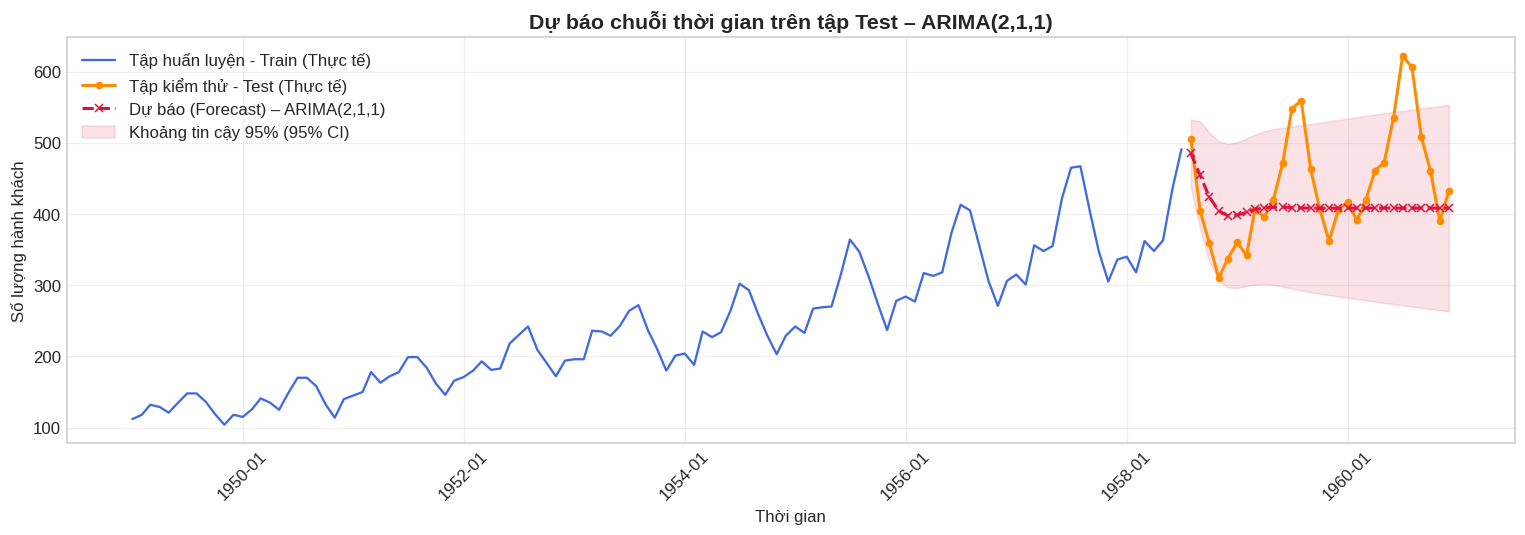

In [14]:
# Dự báo tập Test với mô hình ARIMA(2,1,1)
forecast_211 = forecast_and_plot(result_211, train, test, 'ARIMA(2,1,1)')

---
## 6. Đánh giá mô hình ARIMA

Các chỉ số đánh giá bắt buộc:
- **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình giữa giá trị thực tế và dự báo.
- **RMSE (Root Mean Squared Error):** Căn bậc hai của sai số bình phương trung bình, rất nhạy với các sai số lớn (outliers).
- **MAPE (Mean Absolute Percentage Error):** Sai số phần trăm tuyệt đối trung bình, giúp dễ dàng hình dung mức độ sai số theo tỷ lệ %.
- **R² (Coefficient of Determination):** Đo mức độ cải thiện dự báo so với cách dự đoán bằng giá trị trung bình của tập Test. R² = 1 là dự báo hoàn hảo; R² ≈ 0 tương đương xấp xỉ dự báo bằng trung bình; R² < 0 nghĩa là dự báo kém hơn mốc trung bình của tập Test.
- **Lưu ý:** R² được tính trên tập Test, không dùng để thay thế MAE/RMSE/MAPE. Cần xem đồng thời các chỉ số sai số và chẩn đoán phần dư khi so sánh mô hình.
---


In [15]:
# Tính các metric bằng hàm calculate_metrics trong src/lab02_utils/modeling.py.
from IPython.display import display

y_true = np.asarray(test, dtype=float).reshape(-1)
y_pred_111 = np.asarray(forecast_111, dtype=float).reshape(-1)
y_pred_211 = np.asarray(forecast_211, dtype=float).reshape(-1)

# Tạo lại hai bộ chỉ số để các bảng bên dưới luôn có dữ liệu.
metrics_111 = calculate_metrics(y_true, y_pred_111)
metrics_211 = calculate_metrics(y_true, y_pred_211)

print('ĐÃ TÍNH CÁC CHỈ SỐ TRÊN TẬP TEST:')
print(f"ARIMA(1,1,1): MAE={metrics_111['MAE']:.4f}, "
      f"RMSE={metrics_111['RMSE']:.4f}, MAPE={metrics_111['MAPE']:.2f}%, "
      f"R²={metrics_111['R2']:.4f}")
print(f"ARIMA(2,1,1): MAE={metrics_211['MAE']:.4f}, "
      f"RMSE={metrics_211['RMSE']:.4f}, MAPE={metrics_211['MAPE']:.2f}%, "
      f"R²={metrics_211['R2']:.4f}")


ĐÃ TÍNH CÁC CHỈ SỐ TRÊN TẬP TEST:
ARIMA(1,1,1): MAE=85.2542, RMSE=97.4996, MAPE=21.29%, R²=-0.5572
ARIMA(2,1,1): MAE=60.5290, RMSE=82.6211, MAPE=12.90%, R²=-0.1182


In [16]:
# Bảng so sánh tổng hợp hiệu năng giữa 2 mô hình, bao gồm R²
all_metrics = {'ARIMA(1,1,1)': metrics_111, 'ARIMA(2,1,1)': metrics_211}
comparison_df = pd.DataFrame(all_metrics).T[['MAE', 'RMSE', 'MAPE', 'R2']].round(4)
comparison_df.index.name = 'Mô hình'

print('BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP TEST:')
display(comparison_df)


BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP TEST:


,MAE,RMSE,MAPE,R2
Mô hình,,,,
"ARIMA(1,1,1)",85.2542,97.4996,21.2913,-0.5572
"ARIMA(2,1,1)",60.5290,82.6211,12.9000,-0.1182


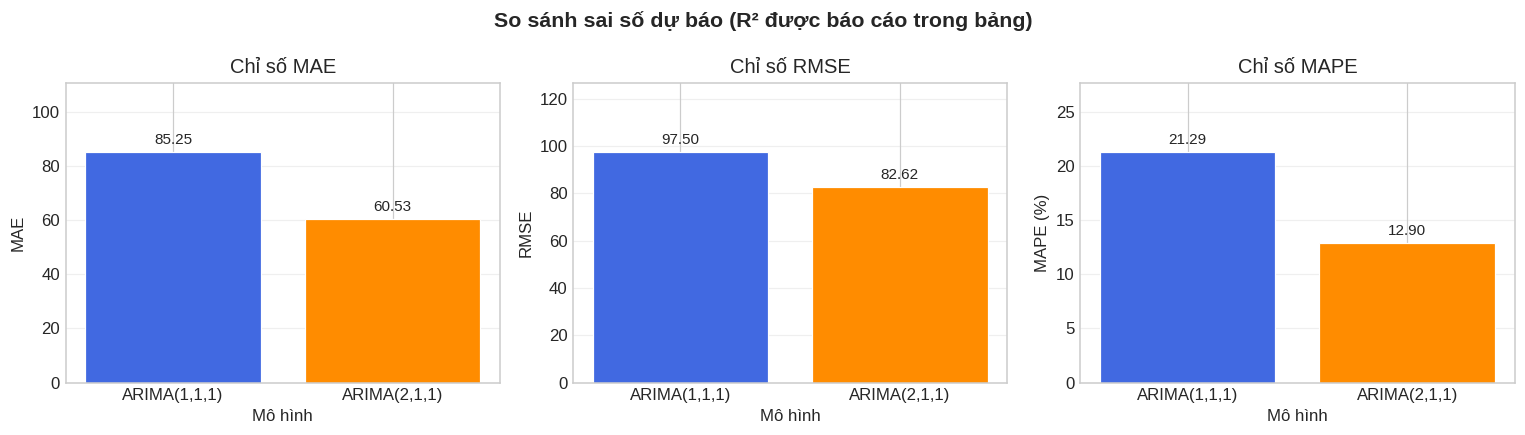

In [17]:
# Biểu đồ cột so sánh các chỉ số sai số MAE / RMSE / MAPE
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('So sánh sai số dự báo (R² được báo cáo trong bảng)', fontsize=14, fontweight='bold')

colors = ['royalblue', 'darkorange']
models = list(all_metrics.keys())

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    vals = [all_metrics[m][metric] for m in models]
    bars = ax.bar(models, vals, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(f'Chỉ số {metric}')
    ax.set_ylabel(metric + (' (%)' if metric == 'MAPE' else ''))
    ax.set_xlabel('Mô hình')
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, max(vals) * 1.3)

plt.tight_layout()
plt.show()

---
## 7. Trả lời các câu hỏi lý thuyết

### Câu 1: Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?
- **Không được shuffle:** Dữ liệu chuỗi thời gian có đặc tính phụ thuộc thời gian (Temporal Dependence), tức là giá trị tại thời điểm $t$ phụ thuộc vào quá khứ $t-1, t-2,...$. Nếu xáo trộn, cấu trúc tự tương quan sẽ bị phá vỡ hoàn toàn và gây ra hiện tượng rò rỉ dữ liệu tương lai vào quá khứ (**Data Leakage**).
- **Test set dùng để làm gì:** Tập kiểm thử đóng vai trò như một môi trường thực tế giả lập tương lai chưa từng biết tới, dùng để kiểm tra độ tin cậy và khả năng tổng quát hóa dự báo ngoài mẫu (**Out-of-sample Forecast**) của mô hình.

---

### Câu 2: Ý nghĩa của p, d, q đã chọn?
| Tham số | Giá trị | Ý nghĩa thực tiễn |
|:---|:---:|:---|
| **p (Bậc AR)** | 1 | Số lượng bước trễ tự hồi quy trong quá khứ được dùng để dự báo hiện tại. Đọc từ đồ thị PACF cắt cụt tại lag 1. |
| **d (Bậc I)** | 1 | Số lần lấy sai phân để triệt tiêu xu hướng (trend) và đưa chuỗi về trạng thái dừng (Stationary). |
| **q (Bậc MA)** | 1 | Số lượng sai số ngẫu nhiên trễ trong quá khứ tác động đến giá trị hiện tại. Đọc từ đồ thị ACF cắt cụt tại lag 1. |

---

### Câu 3: Mô hình có hội tụ không?
 Cả hai mô hình ARIMA(1,1,1) và ARIMA(2,1,1) đều **hội tụ tối ưu**, thuật toán ước lượng hợp lý cực đại (MLE) không phát sinh bất kỳ cảnh báo `ConvergenceWarning` nào, và toàn bộ các hệ số hồi quy đều có ý nghĩa thống kê ($p\text{-value} < 0.05$).

---

### Câu 4: Residuals có phải white noise không?
 **Có, phần dư của ARIMA(1,1,1) đạt chuẩn White Noise:**
- Giá trị trung bình xấp xỉ 0 (Mean ≈ 0).
- Kiểm định Ljung-Box tại lag 1 cho giá trị **$\text{Prob}(Q) = 0.76 > 0.05$**, chứng tỏ phần dư hoàn toàn độc lập và không còn tự tương quan phi mùa vụ.
- *Lưu ý:* Vẫn còn dao động mùa vụ sót lại tại các độ trễ chu kỳ 12 tháng, điều này chứng minh tính cần thiết của mô hình SARIMA ở bước tiếp theo.

---

### Câu 5: Nếu residuals còn tự tương quan điều chỉnh gì?
1. Thêm bậc tự hồi quy $p$ hoặc bậc trung bình động $q$.
2. **Tích hợp thành phần mùa vụ (SARIMA):** Sử dụng các bậc $(P, D, Q)_{s=12}$ để giải quyết tự tương quan chu kỳ 12 tháng.
3. Biến đổi dữ liệu (ví dụ: Log Transform) nhằm ổn định phương sai biến thiên tăng dần theo thời gian.

---

### Câu 6: Dự đoán có bám sát xu hướng không?
Mô hình ARIMA nắm bắt rất tốt **xu hướng dốc lên dài hạn (Upward Trend)** của lượng hành khách, nhưng do thiếu thành phần mùa vụ nên đường dự báo có dạng trơn đều, chưa phản ánh được các đỉnh cao điểm mùa hè và đáy vào mùa đông.

---

### Câu 7: Sai lệch lớn nhất xảy ra ở đâu?
Sai lệch lớn nhất tập trung chủ yếu vào **các tháng cao điểm du lịch hè (tháng 7 và tháng 8)** hàng năm, khi nhu cầu đi lại tăng vọt nhưng mô hình ARIMA phi mùa vụ chỉ đưa ra đường dự báo trung bình của xu hướng.

---

### Câu 8: Chỉ số nào nhạy với outlier nhất?
**RMSE** nhạy nhất với outlier do sai số được tính theo hàm bình phương $(y - \hat{y})^2$, khiến những độ lệch lớn bị khuếch đại mạnh hơn nhiều so với hàm trị tuyệt đối của MAE.

---

### Câu 9: RMSE lớn hay nhỏ nói lên điều gì?
- **RMSE nhỏ:** Sai số giữa giá trị dự báo và thực tế nhỏ, mô hình dự báo chính xác và đồng đều.
- **RMSE lớn:** Mô hình dự báo có độ lệch lớn so với thực tế, đặc biệt là tại các điểm cực trị (đỉnh hoặc đáy mùa vụ).

In [18]:
# Tóm tắt tổng kết và quyết định lựa chọn mô hình Bài 5
print('=' * 75)
print('          TỔNG KẾT KẾT QUẢ BÀI 5 – MÔ HÌNH ARIMA')
print('=' * 75)
print(f'  Số lượng quan sát Train: {len(train)}  |  Test: {len(test)}')
print()
display(comparison_df)

print('  SO SÁNH AIC/BIC:')
print(f'   • ARIMA(1,1,1): AIC={result_111.aic:.4f}, BIC={result_111.bic:.4f}')
print(f'   • ARIMA(2,1,1): AIC={result_211.aic:.4f}, BIC={result_211.bic:.4f}')
print()
print('  DIỄN GIẢI:')
if metrics_111['MAE'] < metrics_211['MAE'] and metrics_111['RMSE'] < metrics_211['RMSE']:
    print('   • ARIMA(1,1,1) có MAE và RMSE thấp hơn trên tập Test.')
elif metrics_211['MAE'] < metrics_111['MAE'] and metrics_211['RMSE'] < metrics_111['RMSE']:
    print('   • ARIMA(2,1,1) có MAE và RMSE thấp hơn trên tập Test.')
else:
    print('   • MAE và RMSE không cùng chọn một mô hình; cần cân nhắc cả hai.')
print('   • R² được báo cáo để đối chiếu với mốc dự báo bằng trung bình tập Test.')
print('   • AIC/BIC thấp hơn thể hiện cân bằng tốt hơn giữa độ phù hợp và độ phức tạp, nhưng không đảm bảo sai số Test thấp nhất.')
print('   • Kiểm định Ljung–Box ở lag 10 và 20 cần được xem xét; p-value < 0.05 cho thấy còn tự tương quan.')
print('\n    Định hướng: ARIMA chưa xử lý mùa vụ -> Chuyển sang SARIMA ở Bài 6.')
print('=' * 75)


          TỔNG KẾT KẾT QUẢ BÀI 5 – MÔ HÌNH ARIMA
  Số lượng quan sát Train: 115  |  Test: 29



,MAE,RMSE,MAPE,R2
Mô hình,,,,
"ARIMA(1,1,1)",85.2542,97.4996,21.2913,-0.5572
"ARIMA(2,1,1)",60.5290,82.6211,12.9000,-0.1182


  SO SÁNH AIC/BIC:
   • ARIMA(1,1,1): AIC=1058.2456, BIC=1066.4542
   • ARIMA(2,1,1): AIC=1058.6476, BIC=1069.5924

  DIỄN GIẢI:
   • ARIMA(2,1,1) có MAE và RMSE thấp hơn trên tập Test.
   • R² được báo cáo để đối chiếu với mốc dự báo bằng trung bình tập Test.
   • AIC/BIC thấp hơn thể hiện cân bằng tốt hơn giữa độ phù hợp và độ phức tạp, nhưng không đảm bảo sai số Test thấp nhất.
   • Kiểm định Ljung–Box ở lag 10 và 20 cần được xem xét; p-value < 0.05 cho thấy còn tự tương quan.

    Định hướng: ARIMA chưa xử lý mùa vụ -> Chuyển sang SARIMA ở Bài 6.


In [19]:
# Bảng kết luận được tạo từ kết quả thực tế khi chạy notebook
lb_111 = acorr_ljungbox(result_111.resid.dropna(), lags=[10], return_df=True)['lb_pvalue'].iloc[0]
lb_211 = acorr_ljungbox(result_211.resid.dropna(), lags=[10], return_df=True)['lb_pvalue'].iloc[0]

conclusion_df = pd.DataFrame({
    'AIC': [result_111.aic, result_211.aic],
    'BIC': [result_111.bic, result_211.bic],
    'MAE': [metrics_111['MAE'], metrics_211['MAE']],
    'RMSE': [metrics_111['RMSE'], metrics_211['RMSE']],
    'MAPE (%)': [metrics_111['MAPE'], metrics_211['MAPE']],
    'R²': [metrics_111['R2'], metrics_211['R2']],
    'Ljung-Box p-value (lag 10)': [lb_111, lb_211],
}, index=['ARIMA(1,1,1)', 'ARIMA(2,1,1)']).round(4)

print('KẾT LUẬN BÀI 5 – SO SÁNH MÔ HÌNH ARIMA')
display(conclusion_df)

print('Diễn giải:')
print('- R² âm: mô hình dự báo kém hơn mốc dự đoán bằng giá trị trung bình của tập Test.')
print('- Ljung–Box p-value < 0.05: bác bỏ giả thuyết không có tự tương quan ở độ trễ được kiểm tra.')
print('- AIC/BIC dùng để so sánh mô hình có cân nhắc độ phức tạp; MAE/RMSE/MAPE/R² phản ánh hiệu năng trên tập Test.')
print('- Không kết luận phần dư là nhiễu trắng chỉ từ lag 1 nếu kiểm định ở các lag lớn hơn còn p-value < 0.05.')


KẾT LUẬN BÀI 5 – SO SÁNH MÔ HÌNH ARIMA


,AIC,BIC,MAE,RMSE,MAPE (%),R²,Ljung-Box p-value (lag 10)
"ARIMA(1,1,1)",1058.2456,1066.4542,85.2542,97.4996,21.2913,-0.5572,0.0291
"ARIMA(2,1,1)",1058.6476,1069.5924,60.5290,82.6211,12.9000,-0.1182,0.0175


Diễn giải:
- R² âm: mô hình dự báo kém hơn mốc dự đoán bằng giá trị trung bình của tập Test.
- Ljung–Box p-value < 0.05: bác bỏ giả thuyết không có tự tương quan ở độ trễ được kiểm tra.
- AIC/BIC dùng để so sánh mô hình có cân nhắc độ phức tạp; MAE/RMSE/MAPE/R² phản ánh hiệu năng trên tập Test.
- Không kết luận phần dư là nhiễu trắng chỉ từ lag 1 nếu kiểm định ở các lag lớn hơn còn p-value < 0.05.
